# 04. Exploratory Data Analysis (EDA) - Dipole Mode Index (DMI / Indian Ocean Dipole)

Notebook ini menganalisis dataset **Dipole Mode Index (DMI)** resmi dari NOAA Physical Sciences Laboratory (PSL) / HadISST.
DMI merupakan indikator utama untuk memantau fenomena **Indian Ocean Dipole (IOD)** di Samudra Hindia tropis.

### Latar Belakang Ilmiah:
- DMI dihitung sebagai selisih anomali suhu permukaan laut (SST) antara:
  - **Kutub Barat (Western Tropical Indian Ocean)**: 50°BT–70°BT, 10°LS–10°LU
  - **Kutub Timur/Tenggara (Southeastern Tropical Indian Ocean)**: 90°BT–110°BT, 10°LS–0° (perairan selatan Jawa & barat Sumatra)
- **Fase IOD Positif (DMI > +0.4°C)**:
  - Perairan barat Samudra Hindia lebih hangat dari normal, sedangkan perairan selatan Jawa–Sumatra lebih dingin akibat *upwelling* yang sangat intens.
  - Dampak bagi Indonesia: Pembentukan awan konvektif tertekan, memicu **musim kemarau ekstrem, kekeringan, dan kebakaran hutan hebat** (contoh: 1997, 2019, 2023).
- **Fase IOD Negatif (DMI < -0.4°C)**:
  - Perairan selatan Jawa–Sumatra lebih hangat dari normal, konveksi meningkat tajam, memicu curah hujan tinggi / kemarau basah di Indonesia bagian barat.
- **Phase-Locking Musiman**: IOD berkembang pada musim dingin belahan bumi selatan (JJA), mencapai puncak pada musim semi (SON), dan punah secara cepat pada Desember–Januari seiring bergantinya arah angin monsun barat laut.

### Tujuan Analisis:
1. Memverifikasi struktur, kelengkapan, dan statistik deret waktu jangka panjang DMI (1870–2026 / 156 tahun).
2. Memvisualisasikan evolusi historis DMI dan mengidentifikasi kejadian IOD Positif dan Negatif ekstrem.
3. Menganalisis fenomena *phase-locking* musiman unik IOD (variansi puncak pada bulan SON).
4. Mengevaluasi struktur autokorelasi (ACF & PACF) dan sifat memori transien Samudra Hindia.
5. Menganalisis kejadian majemuk (*compound climate events*): Interaksi simultan antara IOD (DMI) dan ENSO (ONI) serta dampaknya terhadap kepulauan Indonesia.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from scipy import stats

# Konfigurasi gaya visualisasi
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 150
plt.rcParams['font.size'] = 10

# Konfigurasi Path
DATA_DIR_DMI = Path("dataset/data_dmi") if Path("dataset/data_dmi").exists() else Path("../dataset/data_dmi")
DATA_DIR_ONI = Path("dataset/data_oni") if Path("dataset/data_oni").exists() else Path("../dataset/data_oni")
OUTPUT_DIR = Path("reports/figures") if Path("reports").exists() else Path("../reports/figures")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CSV_DMI = DATA_DIR_DMI / "dmi.csv"
CSV_ONI = DATA_DIR_ONI / "oni.csv"

print(f"Path dataset DMI: {CSV_DMI.resolve()}")
print(f"Path dataset ONI: {CSV_ONI.resolve()}")
print(f"Path output figures: {OUTPUT_DIR.resolve()}")

Path dataset DMI: C:\Coding SDT\VS Code\Python\Semester 5\Proyek Sistem Cerdas\KMRV-model\dataset\data_dmi\dmi.csv
Path dataset ONI: C:\Coding SDT\VS Code\Python\Semester 5\Proyek Sistem Cerdas\KMRV-model\dataset\data_oni\oni.csv
Path output figures: C:\Coding SDT\VS Code\Python\Semester 5\Proyek Sistem Cerdas\KMRV-model\notebook\reports\figures


## 2. Memuat Data dan Pra-pemrosesan

Dataset DMI berisi 3 kolom:
- `Year`: Tahun (1870–2026)
- `Month`: Bulan (1–12)
- `DMI`: Nilai Dipole Mode Index (°C)

Kita mengonversi waktu menjadi representasi datetime dan menghitung moving average untuk mengamati sinyal musiman.

In [2]:
# Memuat dataset
df_dmi = pd.read_csv(CSV_DMI)

# Konversi kolom waktu ke datetime
df_dmi['Date'] = pd.to_datetime(df_dmi['Year'].astype(str) + '-' + df_dmi['Month'].astype(str) + '-01')
df_dmi = df_dmi.sort_values('Date').reset_index(drop=True)

# Moving average 3-bulan untuk menghaluskan fluktuasi jangka pendek
df_dmi['DMI_MA3'] = df_dmi['DMI'].rolling(window=3, center=True).mean()

print("=== INFORMASI DATASET DMI ===")
print(df_dmi.info())
print("\nPengecekan Missing Value:")
print(df_dmi.isnull().sum())
print(f"\nRentang Waktu: {df_dmi['Date'].min().strftime('%B %Y')} s.d. {df_dmi['Date'].max().strftime('%B %Y')} ({len(df_dmi)} bulan)")
print("\nStatistik Deskriptif DMI:")
display(df_dmi[['DMI', 'DMI_MA3']].describe())

=== INFORMASI DATASET DMI ===
<class 'pandas.DataFrame'>
RangeIndex: 1877 entries, 0 to 1876
Data columns (total 5 columns):
 #   Column   Non-Null Count  Dtype         
---  ------   --------------  -----         
 0   Year     1877 non-null   int64         
 1   Month    1877 non-null   int64         
 2   DMI      1877 non-null   float64       
 3   Date     1877 non-null   datetime64[us]
 4   DMI_MA3  1875 non-null   float64       
dtypes: datetime64[us](1), float64(2), int64(2)
memory usage: 73.4 KB
None

Pengecekan Missing Value:
Year       0
Month      0
DMI        0
Date       0
DMI_MA3    2
dtype: int64

Rentang Waktu: January 1870 s.d. May 2026 (1877 bulan)

Statistik Deskriptif DMI:


,DMI,DMI_MA3
count,1877.000000,1875.000000
mean,-0.232217,-0.232350
std,0.346370,0.312522
min,-1.634000,-1.243667
25%,-0.452000,-0.432667
50%,-0.243000,-0.239667
75%,-0.021000,-0.050000
max,1.279000,1.005333


## 3. Visualisasi Deret Waktu Historis Jangka Panjang (1870–2026)

Plot deret waktu 156 tahun berikut menyajikan evolusi fenomena IOD.
- Garis putus-putus merah (+0.4°C) menandai ambang batas **IOD Positif**.
- Garis putus-putus biru (-0.4°C) menandai ambang batas **IOD Negatif**.
- Event-event bersejarah IOD Positif super kuat yang memicu kemarau parah di Indonesia (1961, 1994, 1997, 2019, 2023) ditandai secara visual.

findfont: Failed to find font weight semibold, now using 700.


Gambar disimpan di: C:\Coding SDT\VS Code\Python\Semester 5\Proyek Sistem Cerdas\KMRV-model\notebook\reports\figures\22_dmi_timeseries_longterm.png


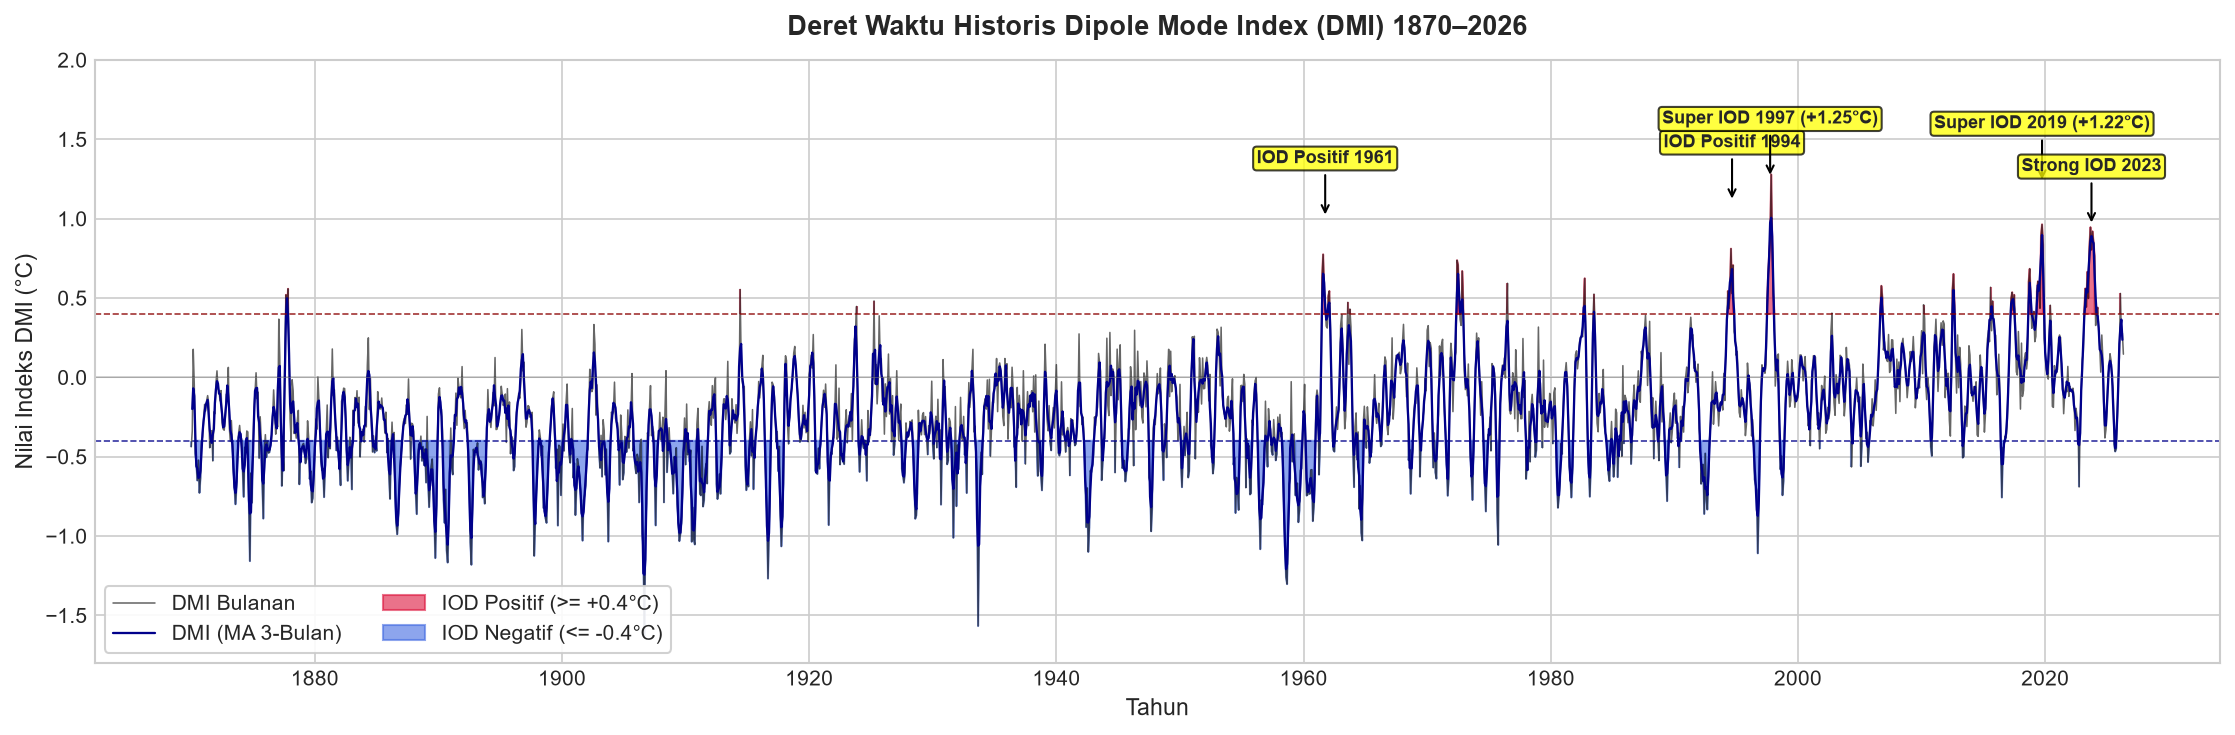

In [3]:
fig, ax = plt.subplots(figsize=(15, 5))

# Plot garis DMI
ax.plot(df_dmi['Date'], df_dmi['DMI'], color='black', linewidth=0.75, alpha=0.6, label='DMI Bulanan')
ax.plot(df_dmi['Date'], df_dmi['DMI_MA3'], color='darkblue', linewidth=1.1, label='DMI (MA 3-Bulan)')

# Shading fase positif dan negatif
ax.fill_between(df_dmi['Date'], df_dmi['DMI'], 0.4, where=(df_dmi['DMI'] >= 0.4),
                color='crimson', alpha=0.6, label='IOD Positif (>= +0.4°C)')
ax.fill_between(df_dmi['Date'], df_dmi['DMI'], -0.4, where=(df_dmi['DMI'] <= -0.4),
                color='royalblue', alpha=0.6, label='IOD Negatif (<= -0.4°C)')

ax.axhline(0.4, color='darkred', linestyle='--', linewidth=0.8, alpha=0.8)
ax.axhline(-0.4, color='darkblue', linestyle='--', linewidth=0.8, alpha=0.8)
ax.axhline(0.0, color='gray', linestyle='-', linewidth=0.5, alpha=0.5)

# Anotasi kejadian IOD Positif super kuat
major_iod_events = [
    ('1961-10-01', 1.0, 'IOD Positif 1961'),
    ('1994-09-01', 1.1, 'IOD Positif 1994'),
    ('1997-10-01', 1.25, 'Super IOD 1997 (+1.25°C)'),
    ('2019-10-01', 1.22, 'Super IOD 2019 (+1.22°C)'),
    ('2023-10-01', 0.95, 'Strong IOD 2023')
]

for d_str, y_val, txt in major_iod_events:
    target_dt = pd.to_datetime(d_str)
    ax.annotate(txt, xy=(target_dt, y_val), xytext=(target_dt, y_val + 0.35),
                arrowprops=dict(facecolor='black', arrowstyle='->', lw=1.0),
                fontsize=8.5, ha='center', fontweight='semibold',
                bbox=dict(boxstyle='round,pad=0.2', facecolor='yellow', alpha=0.75))

ax.set_title("Deret Waktu Historis Dipole Mode Index (DMI) 1870–2026", fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel("Tahun", fontsize=11)
ax.set_ylabel("Nilai Indeks DMI (°C)", fontsize=11)
ax.set_ylim(-1.8, 2.0)
ax.legend(loc='lower left', frameon=True, framealpha=0.9, ncol=2)
plt.tight_layout()

fig_path_22 = OUTPUT_DIR / "22_dmi_timeseries_longterm.png"
plt.savefig(fig_path_22)
print(f"Gambar disimpan di: {fig_path_22.resolve()}")
plt.show()

## 4. Karakteristik Musiman Unik (Phase Locking pada Boreal Autumn / SON)

Berbeda dengan sebagian besar osilasi iklim lainnya, IOD memiliki sifat keterikatan musiman (*seasonal phase locking*) yang sangat kaku:
- IOD berkembang di bulan Juni–Juli, mencapai puncak varians dan amplitudo pada **September, Oktober, dan November (SON)**.
- Pada bulan Desember–Januari, begitu Angin Muson Barat Laut mulai bertiup melintasi ekuator menuju Indonesia, upwelling di selatan Jawa terhenti dan gradien DMI seketika runtuh kembali ke netral.

C:\Users\Nicolaus Prima\AppData\Local\Temp\ipykernel_21172\4064344391.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_dmi, x='Month', y='DMI', ax=axes[0], palette='coolwarm')
C:\Users\Nicolaus Prima\AppData\Local\Temp\ipykernel_21172\4064344391.py:7: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0].set_xticklabels(month_names)


Gambar disimpan di: C:\Coding SDT\VS Code\Python\Semester 5\Proyek Sistem Cerdas\KMRV-model\notebook\reports\figures\23_dmi_monthly_phase_locking.png


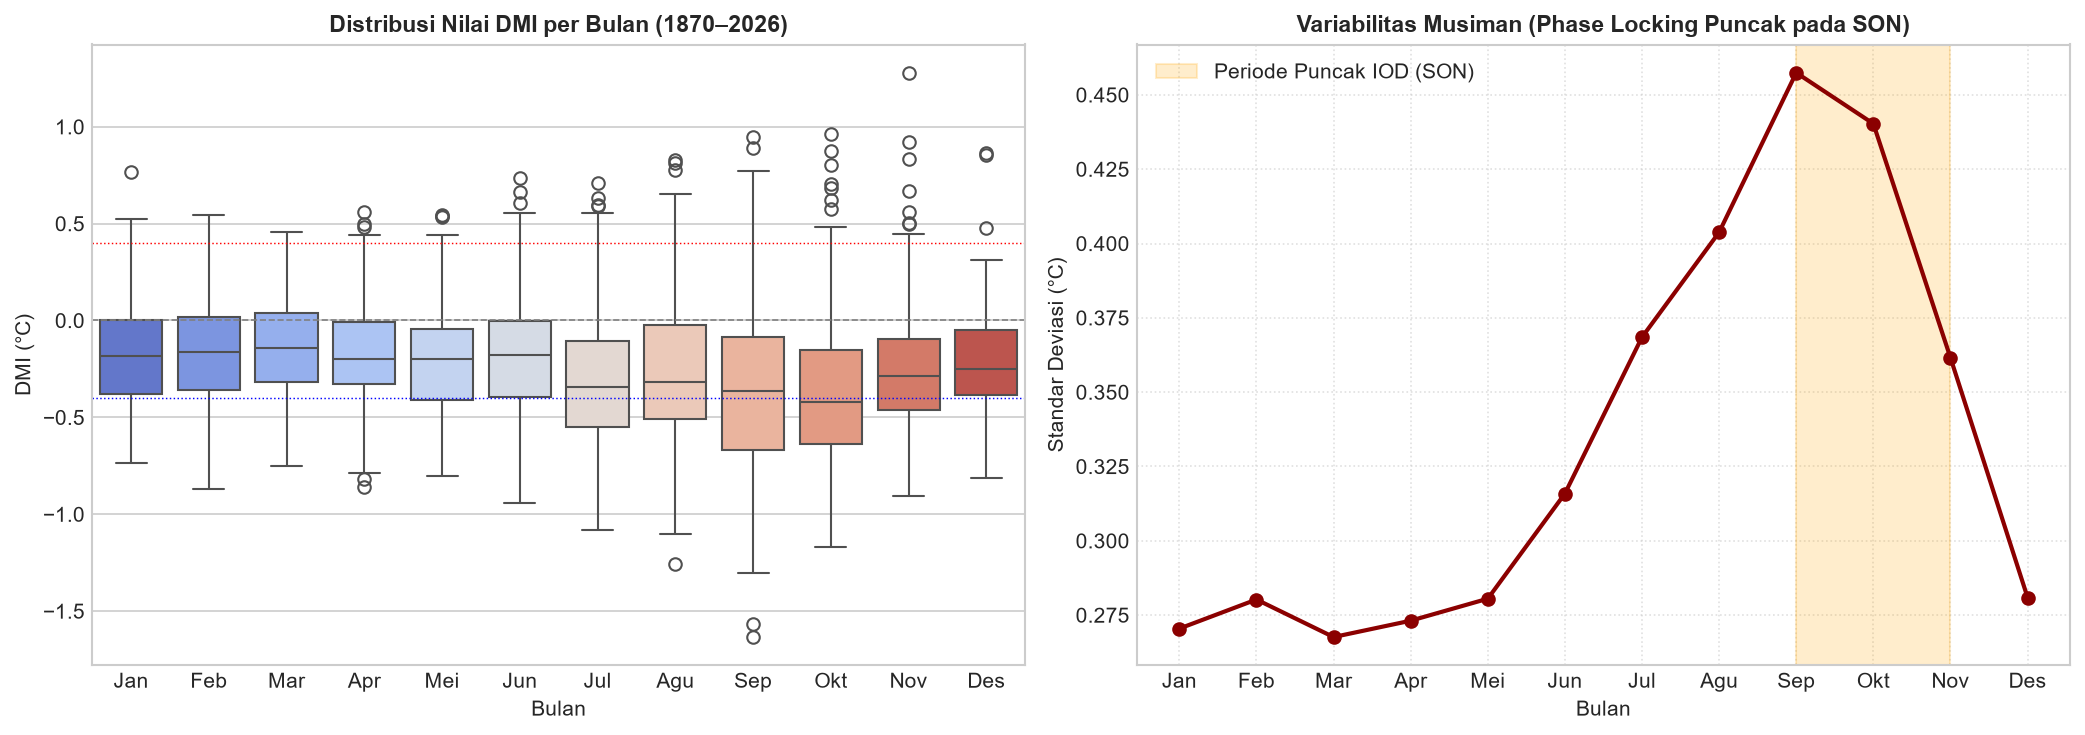

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'Mei', 'Jun', 'Jul', 'Agu', 'Sep', 'Okt', 'Nov', 'Des']

# Plot 1: Boxplot DMI per Bulan
sns.boxplot(data=df_dmi, x='Month', y='DMI', ax=axes[0], palette='coolwarm')
axes[0].set_xticklabels(month_names)
axes[0].axhline(0, color='gray', linestyle='--', linewidth=0.8)
axes[0].axhline(0.4, color='red', linestyle=':', linewidth=0.7)
axes[0].axhline(-0.4, color='blue', linestyle=':', linewidth=0.7)
axes[0].set_title("Distribusi Nilai DMI per Bulan (1870–2026)", fontsize=11, fontweight='bold')
axes[0].set_xlabel("Bulan")
axes[0].set_ylabel("DMI (°C)")

# Plot 2: Standar Deviasi per Bulan (Membuktikan Puncak Variabilitas pada SON)
monthly_std = df_dmi.groupby('Month')['DMI'].std()
axes[1].plot(range(1, 13), monthly_std.values, marker='o', color='darkred', linewidth=2.0)
axes[1].set_xticks(range(1, 13))
axes[1].set_xticklabels(month_names)
axes[1].set_title("Variabilitas Musiman (Phase Locking Puncak pada SON)", fontsize=11, fontweight='bold')
axes[1].set_xlabel("Bulan")
axes[1].set_ylabel("Standar Deviasi (°C)")
axes[1].grid(True, linestyle=':', alpha=0.6)

# Highlight periode SON
axes[1].axvspan(9, 11, color='orange', alpha=0.2, label='Periode Puncak IOD (SON)')
axes[1].legend(loc='upper left')

plt.tight_layout()
fig_path_23 = OUTPUT_DIR / "23_dmi_monthly_phase_locking.png"
plt.savefig(fig_path_23)
print(f"Gambar disimpan di: {fig_path_23.resolve()}")
plt.show()

## 5. Distribusi Kelas IOD & Identifikasi Kejadian Terkuat

Berdasarkan ambang batas standar:
- **IOD Positif**: $DMI \ge +0.4^\circ	ext{C}$
- **IOD Negatif**: $DMI \le -0.4^\circ	ext{C}$
- **Netral**: $-0.4^\circ	ext{C} < DMI < +0.4^\circ	ext{C}$

Di bawah ini dianalisis proporsi kemunculan fase dan visualisasi event-event terkuat sepanjang rekaman data.

Gambar disimpan di: C:\Coding SDT\VS Code\Python\Semester 5\Proyek Sistem Cerdas\KMRV-model\notebook\reports\figures\24_dmi_class_distribution_and_peaks.png


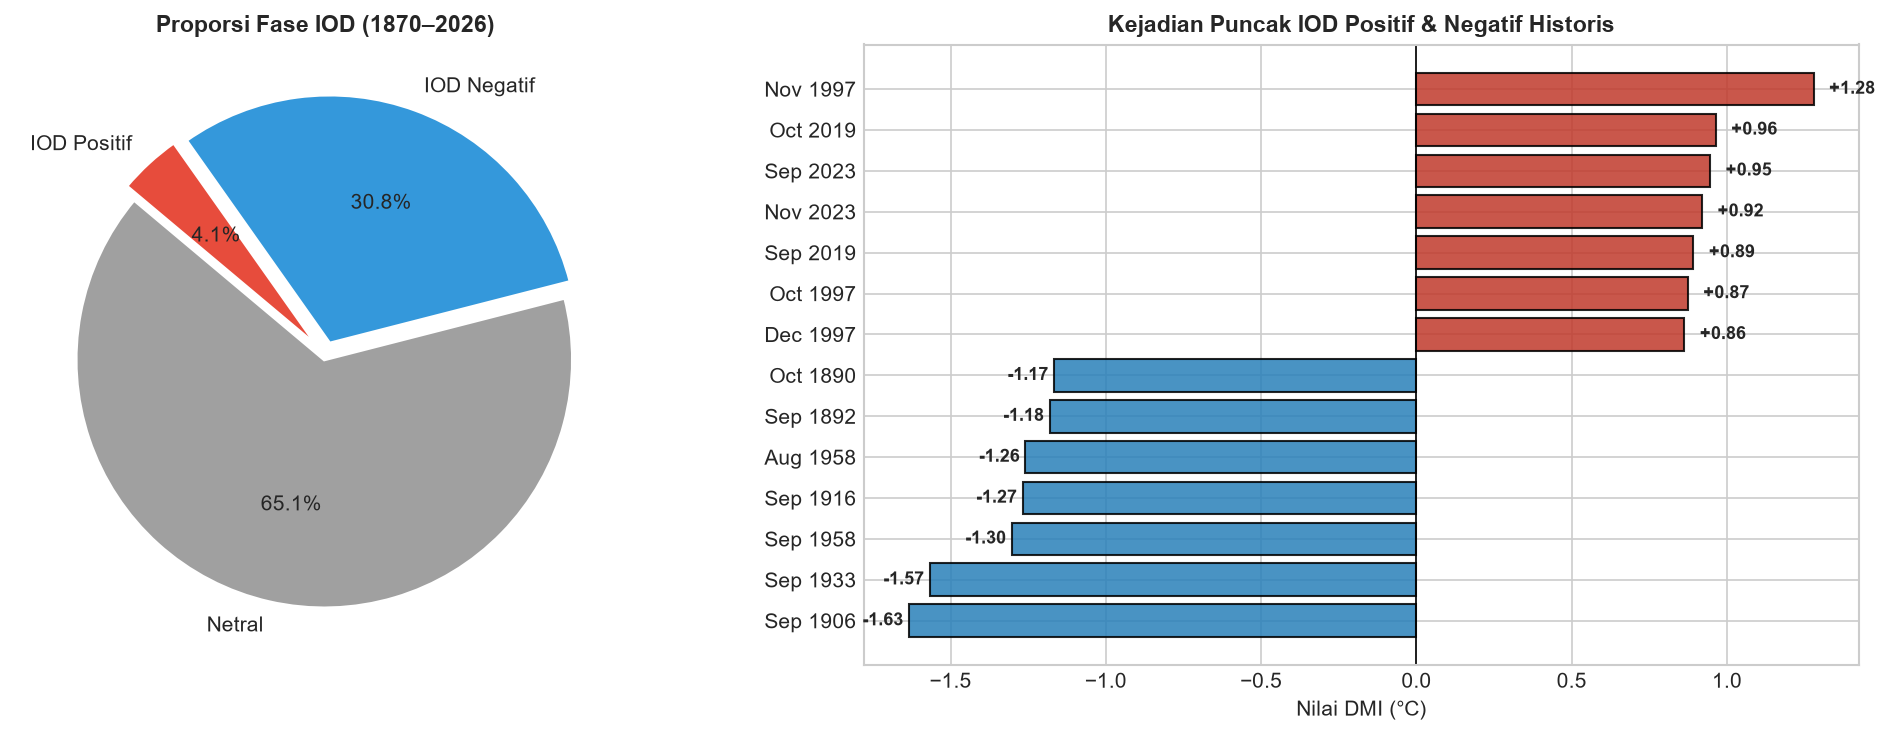

In [5]:
# Pelabelan Kelas IOD
conditions = [
    df_dmi['DMI'] >= 0.4,
    df_dmi['DMI'] <= -0.4
]
choices = ['IOD Positif', 'IOD Negatif']
df_dmi['IOD_Class'] = np.select(conditions, choices, default='Netral')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Pie chart proporsi kelas
class_counts = df_dmi['IOD_Class'].value_counts()
colors = {'Netral': '#a0a0a0', 'IOD Positif': '#e74c3c', 'IOD Negatif': '#3498db'}
axes[0].pie(class_counts, labels=class_counts.index, autopct='%1.1f%%',
            startangle=140, colors=[colors[k] for k in class_counts.index],
            explode=(0.02, 0.05, 0.05), wedgeprops={'edgecolor': 'white', 'linewidth': 1.5})
axes[0].set_title("Proporsi Fase IOD (1870–2026)", fontsize=11, fontweight='bold')

# Plot 2: Top 10 Nilai DMI Tertinggi (IOD Positif) vs Terendah (IOD Negatif)
top_pos = df_dmi.sort_values('DMI', ascending=False).head(7)[['Date', 'DMI']].copy()
top_neg = df_dmi.sort_values('DMI').head(7)[['Date', 'DMI']].copy()
top_combined = pd.concat([top_neg, top_pos]).sort_values('DMI')
top_combined['Label'] = top_combined['Date'].dt.strftime('%b %Y')

bar_cols = ['#2980b9' if x < 0 else '#c0392b' for x in top_combined['DMI']]
axes[1].barh(top_combined['Label'], top_combined['DMI'], color=bar_cols, edgecolor='black', alpha=0.85)
axes[1].axvline(0, color='black', linewidth=0.8)
axes[1].set_title("Kejadian Puncak IOD Positif & Negatif Historis", fontsize=11, fontweight='bold')
axes[1].set_xlabel("Nilai DMI (°C)")
for i, v in enumerate(top_combined['DMI']):
    offset = -0.15 if v < 0 else 0.05
    axes[1].text(v + offset, i, f"{v:+.2f}", va='center', fontweight='bold', fontsize=8.5)

plt.tight_layout()
fig_path_24 = OUTPUT_DIR / "24_dmi_class_distribution_and_peaks.png"
plt.savefig(fig_path_24)
print(f"Gambar disimpan di: {fig_path_24.resolve()}")
plt.show()

## 6. Autokorelasi & Sifat Cepat Reda (Transient Memory) IOD

Berbeda dengan ENSO yang memiliki autokorelasi kuat bertahan melintasi beberapa tahun (memori multi-tahunan), IOD di Samudra Hindia bersifat **transien** dengan pembusukan memori yang sangat cepat setelah lag 4–6 bulan akibat interferensi muson musiman.

Gambar disimpan di: C:\Coding SDT\VS Code\Python\Semester 5\Proyek Sistem Cerdas\KMRV-model\notebook\reports\figures\25_dmi_acf_pacf_analysis.png


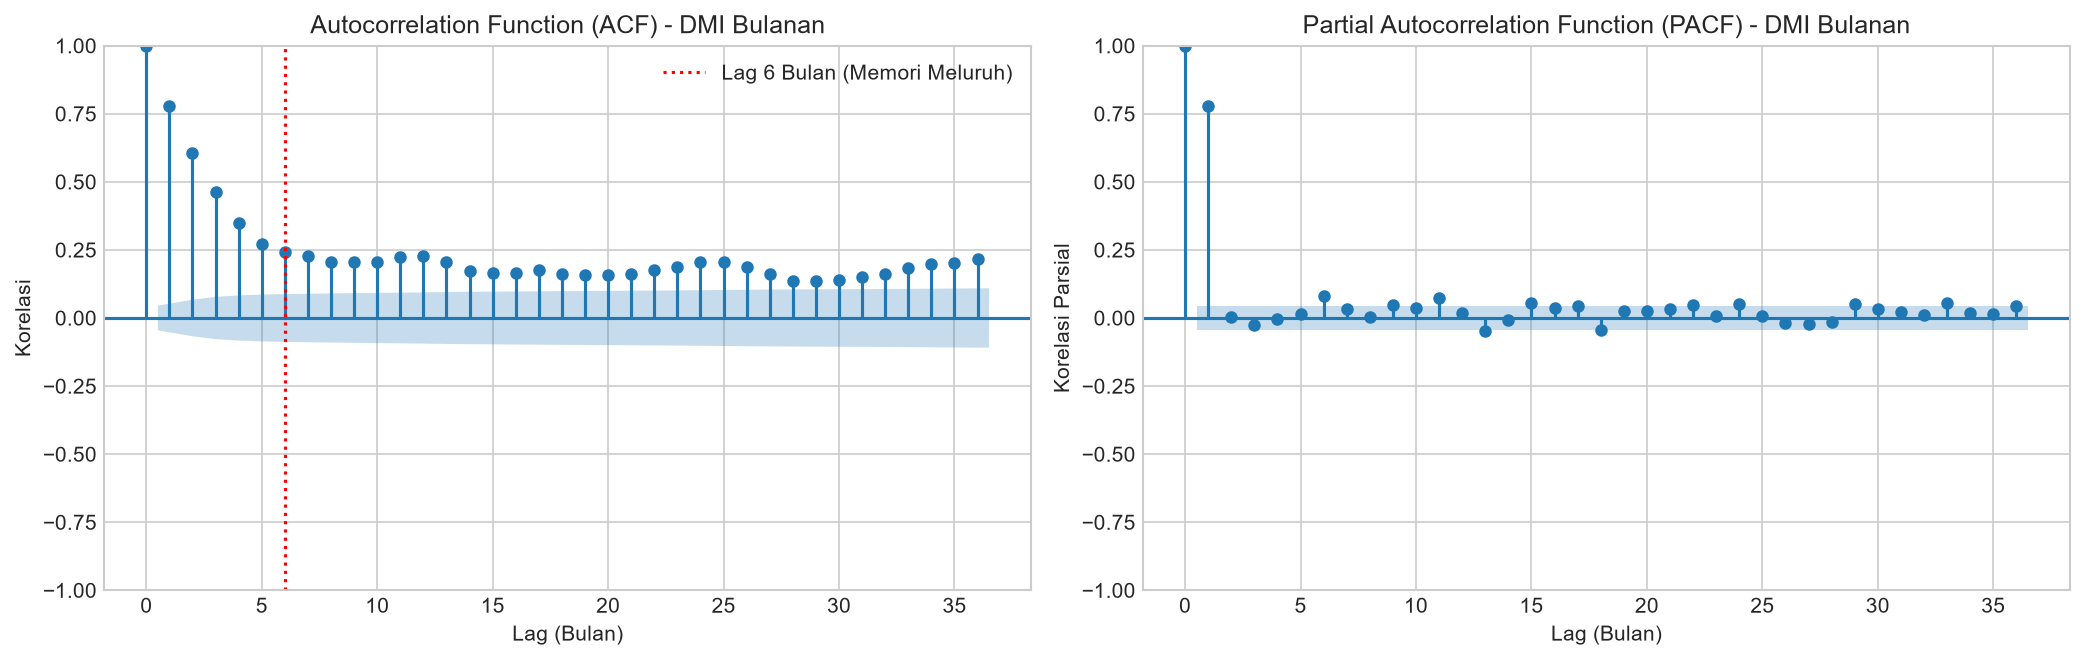

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

plot_acf(df_dmi['DMI'], lags=36, ax=axes[0], title="Autocorrelation Function (ACF) - DMI Bulanan")
plot_pacf(df_dmi['DMI'], lags=36, ax=axes[1], title="Partial Autocorrelation Function (PACF) - DMI Bulanan", method='ywm')

axes[0].set_xlabel("Lag (Bulan)")
axes[0].set_ylabel("Korelasi")
axes[1].set_xlabel("Lag (Bulan)")
axes[1].set_ylabel("Korelasi Parsial")

# Anotasi batas cepat meluruh (transient)
axes[0].axvline(6, color='red', linestyle=':', label='Lag 6 Bulan (Memori Meluruh)')
axes[0].legend(loc='upper right')

plt.tight_layout()
fig_path_25 = OUTPUT_DIR / "25_dmi_acf_pacf_analysis.png"
plt.savefig(fig_path_25)
print(f"Gambar disimpan di: {fig_path_25.resolve()}")
plt.show()

## 7. Analisis Interaksi Majemuk: IOD (DMI) vs ENSO (ONI)

Dampak iklim paling dahsyat terhadap Indonesia terjadi ketika **kejadian majemuk (compound events)** berlangsung secara simultan:
- **Kuadran Kanan Atas: El Niño + IOD Positif**: Menghasilkan *double punch* kekeringan terparah dalam sejarah Indonesia (contoh: 1997 dan 2023).
- **Kuadran Kiri Bawah: La Niña + IOD Negatif**: Memicu anomali curah hujan ekstrem dan banjir berkepanjangan (contoh: 2010 dan 2016).

Gambar disimpan di: C:\Coding SDT\VS Code\Python\Semester 5\Proyek Sistem Cerdas\KMRV-model\notebook\reports\figures\26_dmi_oni_compound_events.png


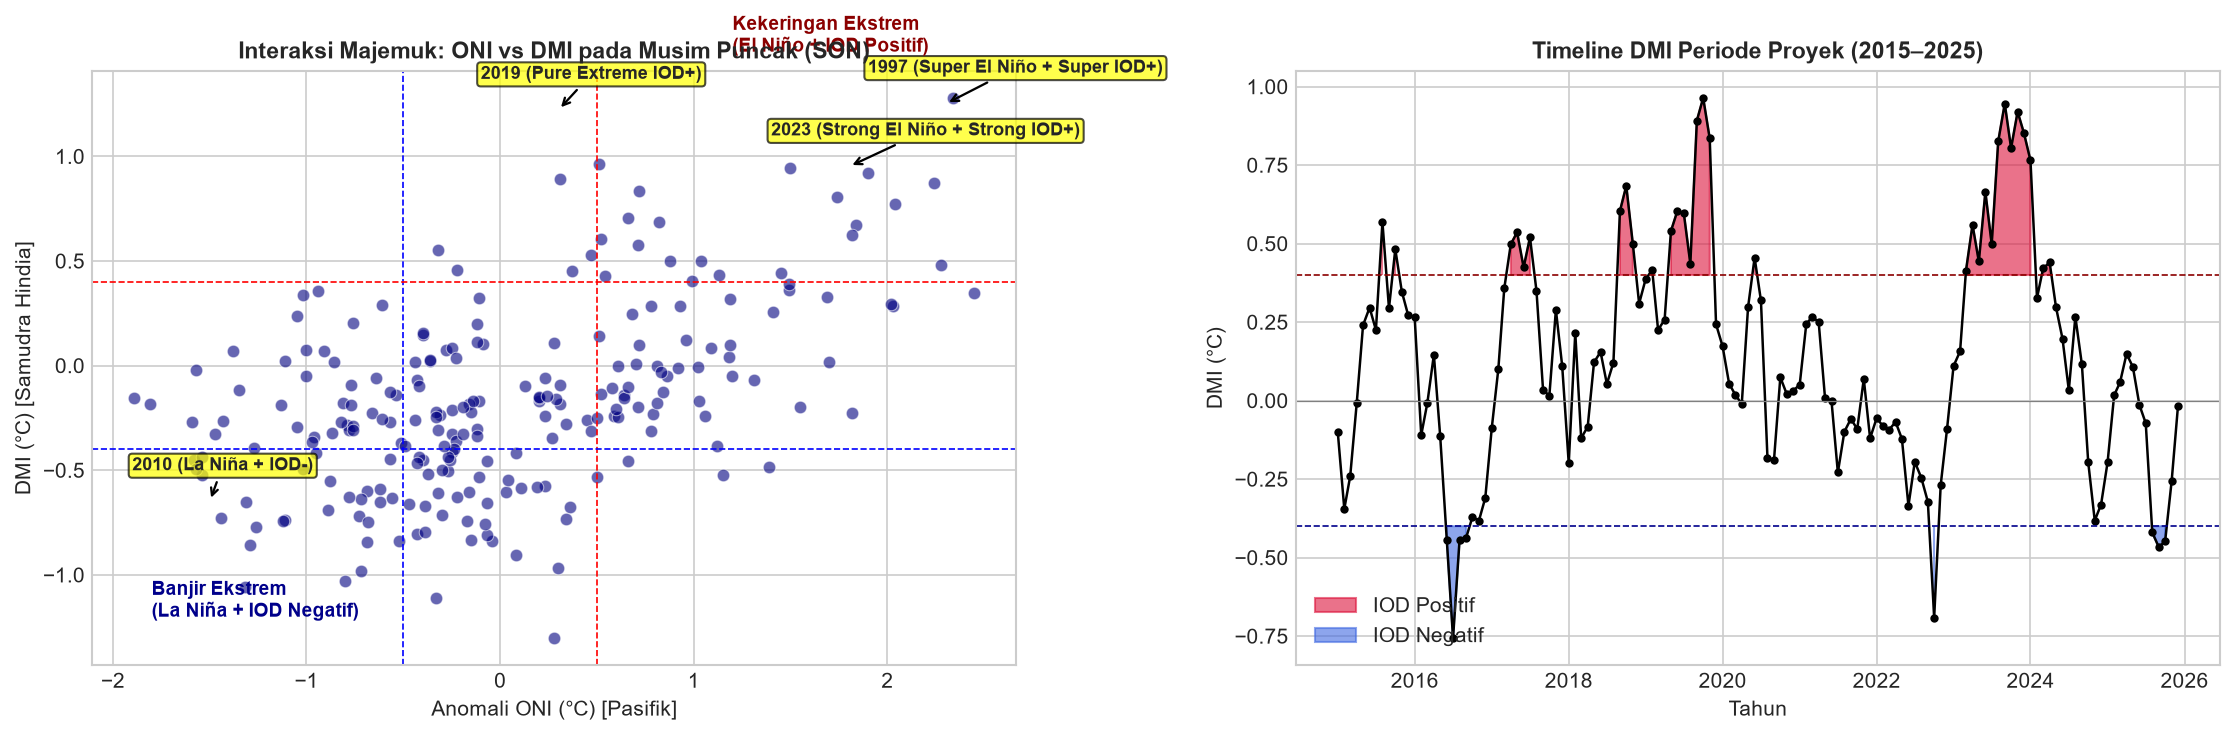

In [7]:
# Memuat ONI dan merge dengan DMI
df_oni_src = pd.read_csv(CSV_ONI)
season_map = {
    'DJF': 1, 'JFM': 2, 'FMA': 3, 'MAM': 4,
    'AMJ': 5, 'MJJ': 6, 'JJA': 7, 'JAS': 8,
    'ASO': 9, 'SON': 10, 'OND': 11, 'NDJ': 12
}
df_oni_src['Month'] = df_oni_src['SEAS'].map(season_map)
df_oni_src['Date'] = pd.to_datetime(df_oni_src['YR'].astype(str) + '-' + df_oni_src['Month'].astype(str) + '-01')

df_interact = pd.merge(df_dmi[['Date', 'DMI', 'Year', 'Month']], df_oni_src[['Date', 'ANOM']], on='Date', how='inner')
df_interact = df_interact.rename(columns={'ANOM': 'ONI_ANOM'})

# Filter hanya musim puncak IOD (bulan SON: September, Oktober, November)
df_son = df_interact[df_interact['Month'].isin([9, 10, 11])].copy()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Plot 1: 4-Kuadran Compound Events (Bulan SON 1950–2025)
sns.scatterplot(data=df_son, x='ONI_ANOM', y='DMI', ax=axes[0], alpha=0.6, color='navy')
axes[0].axvline(0.5, color='red', linestyle='--', linewidth=0.8)
axes[0].axvline(-0.5, color='blue', linestyle='--', linewidth=0.8)
axes[0].axhline(0.4, color='red', linestyle='--', linewidth=0.8)
axes[0].axhline(-0.4, color='blue', linestyle='--', linewidth=0.8)

# Anotasi tahun-tahun compound kritis
critical_years = [(1997, 2.3, 1.25, '1997 (Super El Niño + Super IOD+)'),
                  (2019, 0.3, 1.22, '2019 (Pure Extreme IOD+)'),
                  (2023, 1.8, 0.95, '2023 (Strong El Niño + Strong IOD+)'),
                  (2010, -1.5, -0.65, '2010 (La Niña + IOD-)')]

for yr, x_pt, y_pt, lbl in critical_years:
    axes[0].annotate(lbl, xy=(x_pt, y_pt), xytext=(x_pt - 0.4, y_pt + 0.15),
                     arrowprops=dict(facecolor='black', arrowstyle='->', lw=1.1),
                     fontsize=8.5, fontweight='bold', bbox=dict(boxstyle='round,pad=0.2', facecolor='yellow', alpha=0.7))

axes[0].set_title("Interaksi Majemuk: ONI vs DMI pada Musim Puncak (SON)", fontsize=11, fontweight='bold')
axes[0].set_xlabel("Anomali ONI (°C) [Pasifik]")
axes[0].set_ylabel("DMI (°C) [Samudra Hindia]")
axes[0].text(1.2, 1.5, "Kekeringan Ekstrem\n(El Niño + IOD Positif)", color='darkred', fontweight='bold', fontsize=9)
axes[0].text(-1.8, -1.2, "Banjir Ekstrem\n(La Niña + IOD Negatif)", color='darkblue', fontweight='bold', fontsize=9)

# Plot 2: Timeline DMI pada Periode Proyek (2015–2025)
df_dmi_proj = df_dmi[(df_dmi['Date'] >= '2015-01-01') & (df_dmi['Date'] <= '2025-12-31')].copy()
axes[1].plot(df_dmi_proj['Date'], df_dmi_proj['DMI'], color='black', linewidth=1.2, marker='o', markersize=3)
axes[1].fill_between(df_dmi_proj['Date'], df_dmi_proj['DMI'], 0.4, where=(df_dmi_proj['DMI'] >= 0.4), color='crimson', alpha=0.6, label='IOD Positif')
axes[1].fill_between(df_dmi_proj['Date'], df_dmi_proj['DMI'], -0.4, where=(df_dmi_proj['DMI'] <= -0.4), color='royalblue', alpha=0.6, label='IOD Negatif')
axes[1].axhline(0.4, color='darkred', linestyle='--', linewidth=0.8)
axes[1].axhline(-0.4, color='darkblue', linestyle='--', linewidth=0.8)
axes[1].axhline(0, color='gray', linestyle='-', linewidth=0.6)
axes[1].set_title("Timeline DMI Periode Proyek (2015–2025)", fontsize=11, fontweight='bold')
axes[1].set_xlabel("Tahun")
axes[1].set_ylabel("DMI (°C)")
axes[1].legend(loc='lower left')

plt.tight_layout()
fig_path_26 = OUTPUT_DIR / "26_dmi_oni_compound_events.png"
plt.savefig(fig_path_26)
print(f"Gambar disimpan di: {fig_path_26.resolve()}")
plt.show()

## 8. Kesimpulan & Relevansi terhadap Pemodelan

1. **Phase-Locking yang Sangat Kuat**: Fluktuasi IOD terikat erat pada musim SON. Model prediksi cerdas harus memperhitungkan faktor kalender musiman ini dalam meramalkan anomali iklim regional.
2. **Karakteristik Transien**: Memori IOD relatif pendek (berbeda dengan ENSO yang berdurasi 1–2 tahun). Pemanfaatan lag DMI di atas 6 bulan tidak disarankan karena sinyalnya telah ter-reset oleh monsun.
3. **Compound Events**: Kejadian El Niño yang bertepatan dengan IOD Positif (seperti 2015/2016 dan 2023) menghasilkan sinyal kekeringan yang sangat kuat di Indonesia. Menjadikan DMI sebagai fitur komplementer bersama ONI/SOI akan meningkatkan akurasi model dalam memprediksi dampak cuaca ekstrem.